# 03 · Clustering: user profiler

**DMDW topics:** K-means (elbow + silhouette), agglomerative clustering (dendrogram), DBSCAN (k-distance graph), silhouette comparison.

In [1]:
import pandas as pd
from IPython.display import Image, Markdown, display

from cfiq.config import load_config
from cfiq.db import get_engine, read_sql

cfg = load_config()
engine = get_engine()
REPORTS = cfg["paths"]["reports"]
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
from cfiq.mining import clustering as K

In [2]:
vectors = K.build_user_vectors(read_sql(engine, K.SOLVES_SQL), cfg['mining']['clustering']['min_solved'])
vectors.round(3).head()

,share_algorithms,share_data structures,share_graph theory,share_implementation,share_math,share_strings,rating
handle,,,,,,,
-nameless-,0.400,0.073,0.073,0.184,0.238,0.032,2191.0
.barvay,0.400,0.017,0.000,0.200,0.333,0.050,1428.0
111445,0.364,0.101,0.093,0.194,0.217,0.031,2499.0
123457814,0.452,0.046,0.023,0.174,0.270,0.035,1424.0
5thClassWasGood,0.369,0.072,0.018,0.189,0.261,0.090,1466.0


In [3]:
K.run_clustering(cfg, engine)
pd.read_csv(REPORTS / 'clustering' / 'kmeans_k_selection.csv')

,k,inertia,silhouette
0,2,1617.508536,0.266025
1,3,1373.484260,0.236811
2,4,1242.172115,0.182290
3,5,1139.569688,0.186827
4,6,1049.903018,0.183226
5,7,970.200909,0.188963
6,8,909.875295,0.192954
7,9,849.438043,0.205952
8,10,806.634052,0.175392


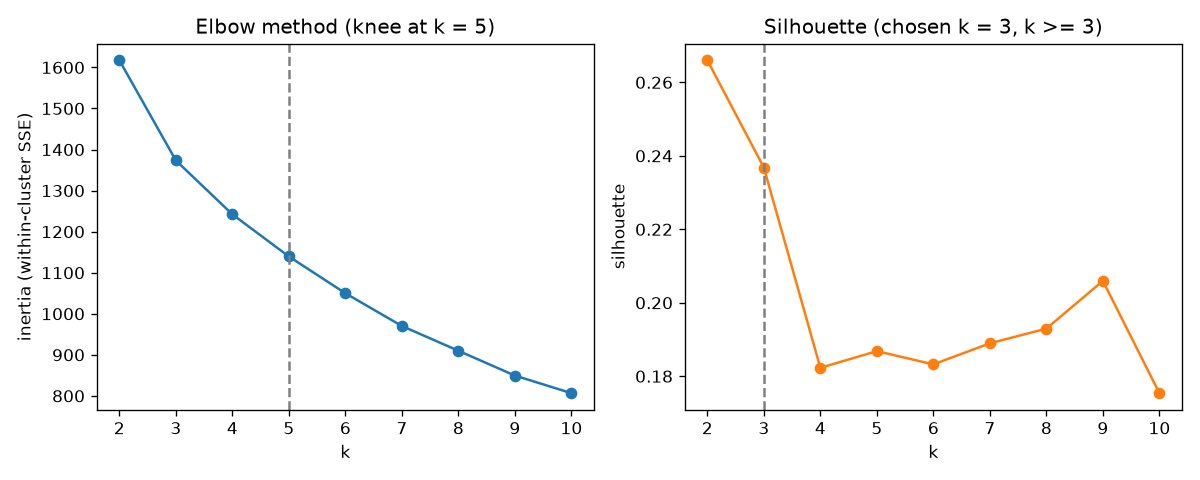

In [4]:
Image(REPORTS / 'clustering' / 'kmeans_elbow_silhouette.png')

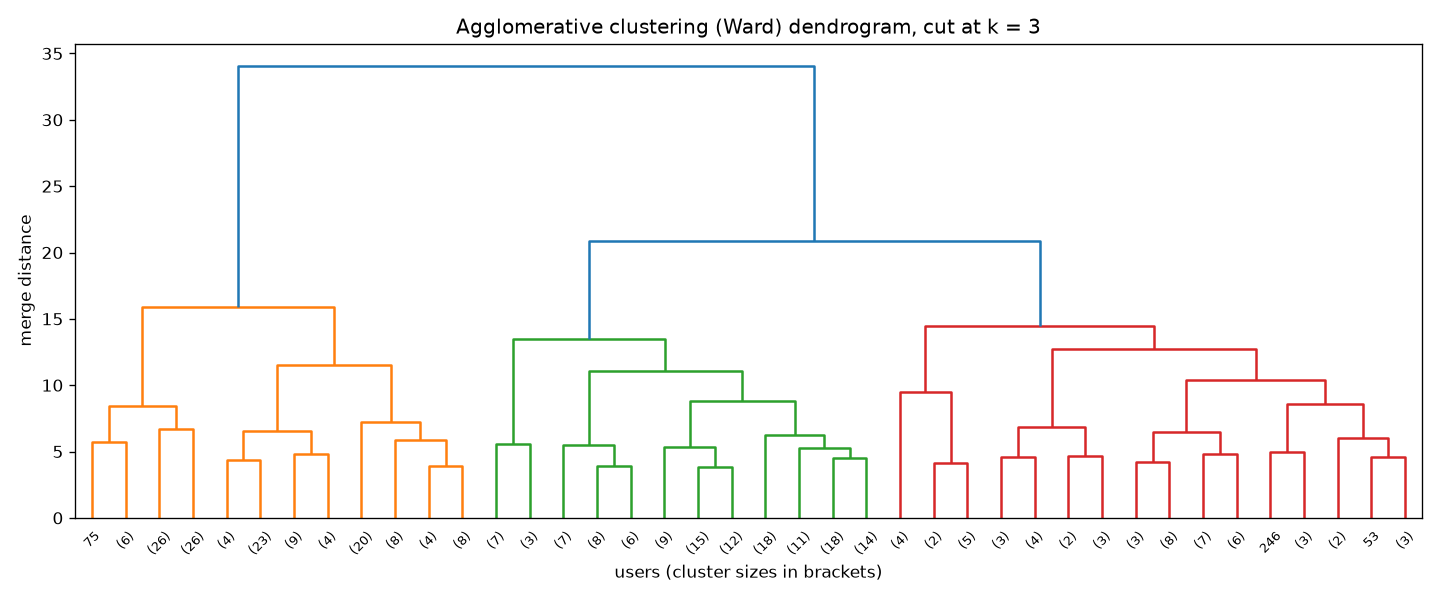

In [5]:
Image(REPORTS / 'clustering' / 'dendrogram.png')

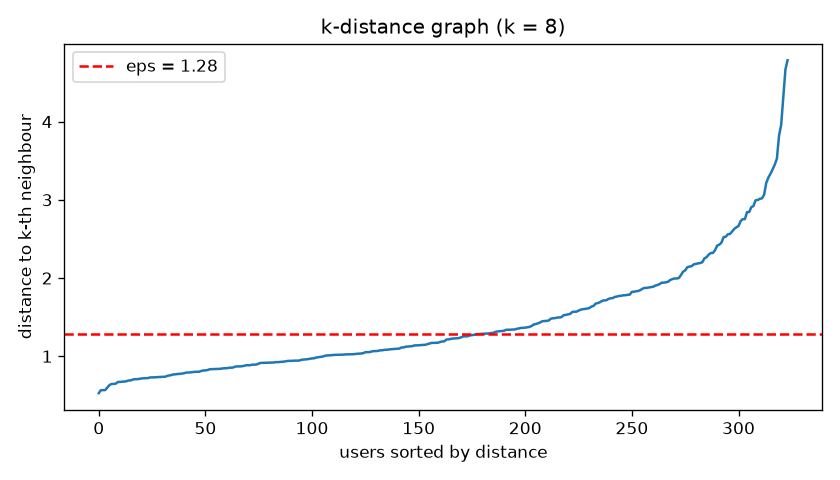

In [6]:
Image(REPORTS / 'clustering' / 'dbscan_k_distance.png')

In [7]:
pd.read_csv(REPORTS / 'clustering' / 'silhouette_comparison.csv')

,algorithm,clusters,noise_points,silhouette
0,kmeans,3,0,0.236811
1,agglomerative,3,0,0.214165
2,dbscan,1,90,NaN


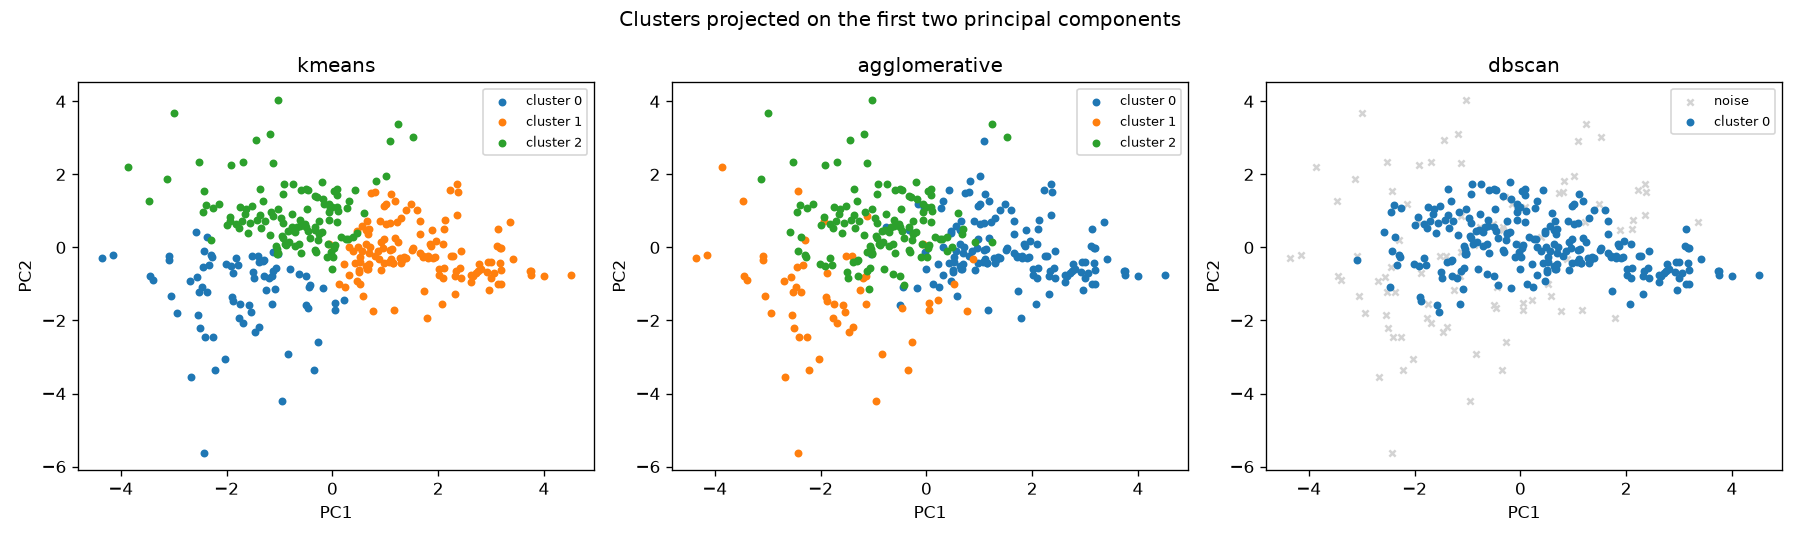

In [8]:
Image(REPORTS / 'clustering' / 'clusters_pca.png')

## Clusters in plain words

In [9]:
text = (REPORTS / 'clustering' / 'summary.md').read_text()
display(Markdown(text[text.index('## kmeans'):text.index('## K-means centroids')]))

## kmeans clusters in plain words

- **Cluster 0** (Pupil / implementation+strings): 74 users averaging 1339 (Pupil); solve relatively more implementation and strings, less graph theory and algorithms.
- **Cluster 1** (Master / graph theory+data structures): 132 users averaging 2278 (Master); solve relatively more graph theory and data structures, less strings and math.
- **Cluster 2** (Specialist / algorithms): 118 users averaging 1578 (Specialist); solve relatively more algorithms, less data structures and graph theory.

## agglomerative clusters in plain words

- **Cluster 0** (Master / data structures+graph theory): 139 users averaging 2238 (Master); solve relatively more data structures and graph theory, less strings and math.
- **Cluster 1** (Pupil / strings+implementation): 57 users averaging 1288 (Pupil); solve relatively more strings and implementation, less algorithms and graph theory.
- **Cluster 2** (Specialist / algorithms): 128 users averaging 1574 (Specialist); solve relatively more algorithms, less data structures and graph theory.

## dbscan clusters in plain words

- **Cluster -1** (noise): 90 users (mean rating 1477) in no dense region: unusual tag mixes.
- **Cluster 0** (Candidate Master / balanced): 234 users averaging 1936 (Candidate Master); tag mix close to the population average.

